# Non-Contact Neonatal Monitoring with Camera-Based PPG
### How good must a non-contact pulse signal be to support early sepsis warning in the NICU?

**Team:** Ishaan Singhal (2024UIC4020) · Ansh Jayara (2024UIC4050) · Raj Aryan (2024UIC4038)
Department of Instrumentation and Control Engineering, NSUT · **Supervisor:** Jyoti Yadav

This notebook contains the experiments behind our end-semester review. Every number here is computed from public data when the notebook runs.

| Part | What it does | Data | Review objective |
|---|---|---|---|
| **A** | Heart-rate pipeline on real PPG: FFT → NLMS motion cancelling → spectral tracking → confidence gate | IEEE SPC 2015 (12 recordings, chest-ECG reference) | Pipeline validated on real PPG |
| **B (E1)** | Camera model: how frame rate and noise corrupt beat timing and HRV features | PhysioNet PICSDB (10 preterm infants, ~3.4 M ECG beats) | O1 |
| **C (E2)** | **ML risk model**: do HeRO-type sepsis patterns survive camera noise? Logistic regression and random forest, leave-one-infant-out | PICSDB + injected sepsis-like patterns | O2 |
| **D (E4)** | Confidence-gate ablation: feature error and AUROC with and without the per-beat quality gate | PICSDB + motion-artefact model | O4 |

> **Scope.** Research prototype, not a medical device. No public neonatal dataset carries sepsis labels, so Part C injects *synthetic* sepsis-like patterns into real infant heart-beat series. It tests whether the signal **survives the camera**, not whether we can diagnose sepsis.

## 0 · Setup

In [1]:
import os, sys, glob, time, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import butter, filtfilt, find_peaks
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve

try:
    import wfdb  # reads PhysioNet annotation files
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'wfdb'], check=True)
    import wfdb

warnings.filterwarnings('ignore')
RNG = np.random.default_rng(42)

# Plot style: validated colour-blind-safe palette, thin lines, quiet grid
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.edgecolor': '#8a8984',
    'axes.titleweight': 'bold', 'axes.titlesize': 11, 'axes.labelsize': 10, 'lines.linewidth': 1.6,
    'legend.frameon': False, 'font.size': 9.5,
})

# Find the data whether we run on Kaggle (/kaggle/input/...) or locally (./data/...)
def find_dir(marker):
    for root in ['/kaggle/input', 'data', '.']:
        hits = glob.glob(os.path.join(root, '**', marker), recursive=True)
        if hits:
            return os.path.dirname(hits[0])
    raise FileNotFoundError(f'{marker} not found. Attach the dataset (see the README).')

SPC_DIR = find_dir('DATA_01_TYPE01.mat')
PICS_DIR = find_dir('infant1_ecg.qrsc')
FIG_DIR = '/kaggle/working/figures' if os.path.isdir('/kaggle/working') else 'figures'
os.makedirs(FIG_DIR, exist_ok=True)
print('SPC 2015 :', SPC_DIR)
print('PICSDB   :', PICS_DIR)
print('Figures  :', FIG_DIR)

def save(fig, name):
    fig.savefig(f'{FIG_DIR}/{name}.png', bbox_inches='tight')

SPC 2015 : data/spc2015
PICSDB   : data/picsdb
Figures  : figures


---
## Part A · Heart-rate pipeline on real PPG (IEEE SPC 2015)

**Data.** 12 recordings of subjects running on a treadmill at changing speed (Zhang et al., TROIKA, IEEE TBME 2015). Each has two wrist PPG channels, a 3-axis accelerometer and a simultaneous chest ECG, sampled at 125 Hz. The reference heart rate comes from the ECG in 8 s windows every 2 s.

**Why this data?** Running motion is a harsh stand-in for the motion artefacts that dominate NICU video. Here we can measure error against ECG ground truth.

**Pipeline stages, each added on top of the previous one:**
1. **Plain FFT.** Band-pass 0.4–4 Hz, then take the highest spectral peak in 40–220 bpm.
2. **+ NLMS.** An adaptive filter uses each accelerometer axis as a noise reference and subtracts the motion it can predict from the PPG.
3. **+ Tracking.** Suppress spectral peaks that coincide with motion peaks, then choose the candidate closest to the previous estimate (±12 bpm).
4. **+ Confidence and lock-loss reset.** Confidence is the fraction of spectral power near the chosen peak, penalised when that peak sits on a motion peak. Three low-confidence windows in a row force re-acquisition.
5. **+ Gate.** Windows with confidence below the threshold are **withheld** instead of displayed. This is what the bedside monitor would do.

In [2]:
FS = 125                      # SPC 2015 sampling rate (Hz)
WIN, STEP = 8 * FS, 2 * FS    # 8 s window, 2 s step (matches the ECG reference)
NFFT = 8192                   # zero-padded FFT -> 0.9 bpm bin spacing
FREQS = np.fft.rfftfreq(NFFT, 1 / FS) * 60      # FFT bins in bpm
BAND = (FREQS >= 40) & (FREQS <= 220)           # physiological HR search band
CONF_THR = 0.12                                  # confidence gate threshold
SPC_NAMES = sorted(os.path.basename(f)[5:-4] for f in glob.glob(f'{SPC_DIR}/DATA_*.mat'))


def bandpass(x, lo, hi, fs, order=4):
    b, a = butter(order, [lo, hi], btype='band', fs=fs)
    return filtfilt(b, a, x, axis=-1)


def load_spc(name):
    """Return (2 PPG channels, 3 accelerometer axes, ECG reference HR per window)."""
    sig = loadmat(f'{SPC_DIR}/DATA_{name}.mat')['sig']   # rows: ECG, PPG1, PPG2, accX, accY, accZ
    ref = loadmat(f'{SPC_DIR}/REF_{name}.mat')['BPM0'].ravel()
    return bandpass(sig[1:3], 0.4, 4, FS), bandpass(sig[3:6], 0.4, 4, FS), ref


def nlms(d, refs, order=16, mu=0.003):
    """Cascade NLMS: remove the part of the PPG predictable from each accelerometer axis."""
    e = d / np.std(d)
    for r in refs:
        r = r / (np.std(r) + 1e-12)
        X = sliding_window_view(np.pad(r, (order - 1, 0)), order)[:, ::-1]  # tapped delay line
        w = np.zeros(order)
        out = np.empty_like(e)
        for n in range(len(e)):
            out[n] = e[n] - w @ X[n]                               # error = cleaned PPG sample
            w += mu * out[n] * X[n] / (X[n] @ X[n] + 1e-6)         # normalised LMS update
        e = out
    return e


def spectrum(x):
    return np.abs(np.fft.rfft(x * np.hanning(len(x)), NFFT)) ** 2


def estimate_hr(ppg, acc, n_win, suppress=True, track=True, reset=True, motion_conf=True,
                k_reset=3, search=12, alpha=0.6, motion_thr=0.08):
    """Return HR estimate and confidence for every 8 s window."""
    hr, conf = np.zeros(n_win), np.zeros(n_win)
    prev, low_run = None, 0
    for i in range(n_win):
        s = slice(i * STEP, i * STEP + WIN)
        P = sum(spectrum(c[s]) for c in ppg)
        P = P / P[BAND].sum()                                   # normalised PPG spectrum
        A = sum(spectrum(a[s]) for a in acc)
        A = A / A[BAND].sum()                                   # normalised motion spectrum
        Ps = P
        if suppress:                                            # attenuate bins at motion peaks
            mpk, _ = find_peaks(np.where(BAND, A, 0), height=0.3 * A[BAND].max())
            mask = np.zeros_like(P, bool)
            for p in mpk:
                mask |= np.abs(FREQS - FREQS[p]) <= 3
            Ps = np.where(mask, P * 0.2, P)
        pk, _ = find_peaks(np.where(BAND, Ps, 0))
        pk = pk[np.argsort(Ps[pk])[::-1][:5]]                   # top-5 candidate peaks
        if track and prev is not None:
            near = pk[np.abs(FREQS[pk] - prev) <= search]
            est = FREQS[near[np.argmax(Ps[near] / (1 + np.abs(FREQS[near] - prev) / search))]] \
                if len(near) else prev                          # no candidate: hold last value
        else:
            est = FREQS[pk[0]]
        around = np.abs(FREQS - est) <= 4
        conf[i] = P[around].sum()                               # spectral concentration
        if motion_conf and A[around].sum() > motion_thr:        # estimate sits on a motion peak
            conf[i] *= 0.3
        if track:
            prev = est if prev is None else alpha * est + (1 - alpha) * prev
            hr[i] = prev
            low_run = low_run + 1 if conf[i] < CONF_THR else 0
            if reset and low_run >= k_reset:                    # lock-loss reset
                prev, low_run = None, 0
        else:
            hr[i] = est
    return hr, conf

In [3]:
t0 = time.time()
STAGES = ['Plain FFT', '+ NLMS', '+ Tracking', '+ Conf. & reset']
spc_rows, spc_traces = [], {}
for name in SPC_NAMES:
    ppg, acc, ref = load_spc(name)
    clean = np.array([nlms(c, acc) for c in ppg])
    n = len(ref)
    est = {
        'Plain FFT':       estimate_hr(ppg,   acc, n, suppress=False, track=False, motion_conf=False),
        '+ NLMS':          estimate_hr(clean, acc, n, suppress=False, track=False, motion_conf=False),
        '+ Tracking':      estimate_hr(clean, acc, n, reset=False, motion_conf=False),
        '+ Conf. & reset': estimate_hr(clean, acc, n),
    }
    hr, conf = est['+ Conf. & reset']
    kept = conf >= CONF_THR
    row = {'recording': name}
    row.update({k: np.mean(np.abs(v[0] - ref)) for k, v in est.items()})
    row['Gated (kept windows)'] = np.mean(np.abs(hr - ref)[kept]) if kept.any() else np.nan
    row['coverage %'] = 100 * kept.mean()
    spc_rows.append(row)
    spc_traces[name] = (ref, est, kept)
spc = pd.DataFrame(spc_rows).set_index('recording')
print(f'processed 12 recordings in {time.time() - t0:.0f} s')

summary = pd.DataFrame({'mean': spc.mean(), 'median': spc.median()}).T
display(spc.round(2))
print('Mean absolute error (bpm) across the 12 recordings:')
display(summary.round(2))

processed 12 recordings in 16 s


,Plain FFT,+ NLMS,+ Tracking,+ Conf. & reset,Gated (kept windows),coverage %
recording,,,,,,
01_TYPE01,22.66,17.70,52.19,8.73,1.97,58.11
02_TYPE02,25.87,13.05,42.68,7.06,0.99,74.32
03_TYPE02,24.06,6.86,84.62,7.36,1.74,85.00
04_TYPE01,19.06,35.35,14.71,35.90,32.52,51.40
04_TYPE02,11.13,4.30,1.60,2.90,0.96,87.67
05_TYPE02,6.30,4.35,1.06,1.93,0.87,90.41
06_TYPE02,23.83,4.88,79.51,2.41,1.33,77.33
07_TYPE02,7.88,3.17,1.08,2.04,0.94,77.62
08_TYPE02,18.33,1.74,1.08,1.09,1.08,95.00


Mean absolute error (bpm) across the 12 recordings:


,Plain FFT,+ NLMS,+ Tracking,+ Conf. & reset,Gated (kept windows),coverage %
mean,18.66,12.01,31.91,9.68,5.71,73.75
median,20.86,5.48,8.16,3.77,1.15,77.97


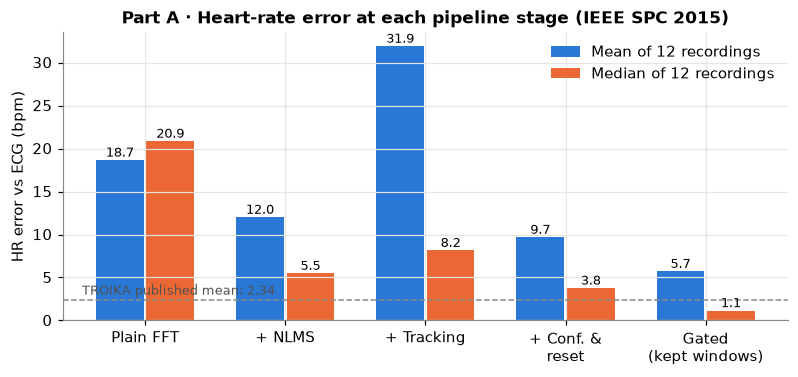

Gate keeps 74% of windows on average.


In [4]:
cols = STAGES + ['Gated (kept windows)']
fig, ax = plt.subplots(figsize=(8.5, 3.4))
x = np.arange(len(cols))
ax.bar(x - 0.18, summary.loc['mean', cols], 0.34, color=BLUE, label='Mean of 12 recordings')
ax.bar(x + 0.18, summary.loc['median', cols], 0.34, color=ORANGE, label='Median of 12 recordings')
for xi, (m, md) in enumerate(zip(summary.loc['mean', cols], summary.loc['median', cols])):
    ax.text(xi - 0.18, m + 0.4, f'{m:.1f}', ha='center', fontsize=8.5)
    ax.text(xi + 0.18, md + 0.4, f'{md:.1f}', ha='center', fontsize=8.5)
ax.axhline(2.34, color=GREY, ls='--', lw=1)
ax.text(-0.45, 3.0, 'TROIKA published mean: 2.34', ha='left', color='#52514e', fontsize=8.5)
ax.set_xticks(x, [c.replace(' & ', ' &\n').replace(' (', '\n(') for c in cols])
ax.set_ylabel('HR error vs ECG (bpm)')
ax.set_title('Part A · Heart-rate error at each pipeline stage (IEEE SPC 2015)')
ax.legend(loc='upper right')
save(fig, 'A1_stage_errors'); plt.show()
print(f"Gate keeps {spc['coverage %'].mean():.0f}% of windows on average.")

**The silent failure.** Without the reset, the tracker can lock onto a motion rhythm (arm swing is often about half the HR) and stay there. Its spectral confidence can still look *high* while it is wrong. Below is the worst recording for each tracker.

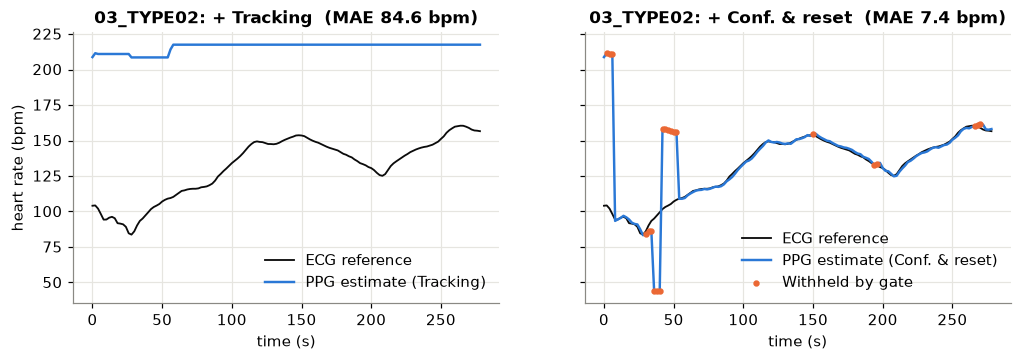

Tracking without reset: 6 of 12 recordings end with MAE > 10 bpm (tracker locked on a wrong peak).
With reset + gate: 2 of 12 still exceed 10 bpm on kept windows.


In [5]:
worst = (spc['+ Tracking'] - spc['+ Conf. & reset']).idxmax()
ref, est, kept = spc_traces[worst]
t = np.arange(len(ref)) * 2
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, key in zip(axes, ['+ Tracking', '+ Conf. & reset']):
    ax.plot(t, ref, color='#0b0b0b', lw=1.2, label='ECG reference')
    ax.plot(t, est[key][0], color=BLUE, label=f'PPG estimate ({key.strip("+ ")})')
    if key == '+ Conf. & reset':
        ax.scatter(t[~kept], est[key][0][~kept], s=10, color=ORANGE, zorder=3, label='Withheld by gate')
    ax.set_title(f'{worst}: {key}  (MAE {spc.loc[worst, key]:.1f} bpm)')
    ax.set_xlabel('time (s)')
    ax.legend(loc='lower right')
axes[0].set_ylabel('heart rate (bpm)')
save(fig, 'A2_silent_failure'); plt.show()

n_fail = int((spc['+ Tracking'] > 10).sum())
print(f'Tracking without reset: {n_fail} of 12 recordings end with MAE > 10 bpm (tracker locked on a wrong peak).')
print(f"With reset + gate: {int((spc['Gated (kept windows)'] > 10).sum())} of 12 still exceed 10 bpm on kept windows.")

**Part A, takeaways**
* Median error across the 12 recordings drops from **20.9 bpm (plain FFT) to 3.8 bpm** with NLMS, tracking, confidence and reset, an ~82% reduction. On the windows the gate keeps (~74%), the median error is **~1.1 bpm**.
* A tracker **without** a lock-loss reset fails silently on **6 of 12** recordings (it locks onto a wrong peak and never recovers), so a confidence gate is essential.
* Two recordings (04_TYPE01, 10_TYPE02) still fail even with the gate. These are honest failure cases to show.
* Spectral concentration alone is not a safe confidence measure. Checking whether the estimate coincides with a motion peak is what catches the arm-swing lock.
* Honest limitation: the pipeline parameters (NLMS step size, thresholds) were set with a small sweep on these same 12 recordings, and there is no held-out set. The published TROIKA result (2.34 bpm) is better than ours.

---
## Data for Parts B–D · PhysioNet PICSDB (preterm infants)

The **Preterm Infant Cardio-Respiratory Signals Database** has 10 preterm infants with 20–70 h of ECG each, plus reference **R-peak annotations** and **bradycardia onsets**. We use the R-peak times as the **true heartbeat times** of a real neonate. A camera would see the same heartbeats as pulse peaks, but with noise, missed beats and frame-rate quantisation.

We cut each infant's recording into 5-minute windows (the feature window from our methodology slide). We keep windows with no gaps in the ECG annotations, and sample 30 at random per infant.

In [6]:
WIN_S = 300           # 5-minute feature window
N_PER_INFANT = 30

pics_windows, pics_stats = [], []
for i in range(1, 11):
    rec = f'{PICS_DIR}/infant{i}_ecg'
    fs = wfdb.rdheader(rec).fs
    beats = wfdb.rdann(rec, 'qrsc').sample / fs           # R-peak times (s)
    brady = wfdb.rdann(rec, 'atr').sample / fs            # bradycardia onsets (s)
    rr = np.diff(beats)
    pics_stats.append({'infant': i, 'hours': beats[-1] / 3600, 'beats': len(beats),
                       'median HR (bpm)': 60 / np.median(rr), 'bradycardias': len(brady)})
    # candidate starts: every 5 min; keep windows with no annotation gap > 2 s
    starts = np.arange(beats[0], beats[-1] - WIN_S, WIN_S)
    good = []
    for s in starts:
        b = beats[(beats >= s) & (beats < s + WIN_S)]
        if len(b) > 200 and np.diff(b).max() < 2.0:
            good.append(b - s)
    for j in RNG.choice(len(good), N_PER_INFANT, replace=False):
        pics_windows.append((i, good[j]))

display(pd.DataFrame(pics_stats).set_index('infant').round(1))
print(f'{len(pics_windows)} five-minute windows from 10 infants')

,hours,beats,median HR (bpm),bradycardias
infant,,,,
1,45.6,419233,154.6,77
2,43.8,333604,129.9,72
3,43.7,335087,129.3,80
4,46.8,465565,165.7,66
5,48.8,411149,141.5,72
6,48.6,395392,136.4,56
7,20.3,195072,160.4,34
8,24.6,204532,139.5,28
9,70.3,626628,149.3,97


300 five-minute windows from 10 infants


### Features (methodology step 9)
Computed on the inter-beat-interval (IBI) series of each 5-minute window:

| Feature | Meaning | Why it matters for sepsis |
|---|---|---|
| Mean HR | average heart rate | tachycardia |
| SDNN | SD of beat intervals | overall variability, falls in sepsis (Griffin 2001) |
| RMSSD | beat-to-beat variability | vagal tone |
| Sample asymmetry | interval spread above vs below the median | rises with decelerations (HeRO) |
| Sample entropy | regularity of the series | falls in sepsis (HeRO) |
| Decelerations | number of HR dips below 2/3 of baseline | transient decelerations (HeRO) |

In [7]:
FEATURES = ['mean_hr', 'sdnn_ms', 'rmssd_ms', 'asymmetry', 'samp_en', 'decels']


def sample_entropy(x, m=2, r_frac=0.2):
    x = np.asarray(x, float)
    r = r_frac * x.std()
    if len(x) < m + 2 or r == 0:
        return np.nan
    def count(mm):
        T = sliding_window_view(x, mm)[: len(x) - m]
        d = np.max(np.abs(T[:, None, :] - T[None, :, :]), axis=2)      # Chebyshev distance
        return (np.sum(d <= r) - len(T)) / 2                          # matched pairs, no self-match
    B, A = count(m), count(m + 1)
    return -np.log(A / B) if A > 0 and B > 0 else np.nan


def ibi_features(ibi, valid=None):
    """HRV features from an IBI series (seconds). `valid` marks IBIs accepted by the quality gate."""
    ibi = np.asarray(ibi, float)
    if valid is None:
        valid = np.ones(len(ibi), bool)
    v = ibi[valid]
    if len(v) < 50:
        return dict.fromkeys(FEATURES, np.nan)
    pair = valid[1:] & valid[:-1]                         # successive differences only across good pairs
    dif = np.diff(ibi)[pair]
    dev = v - np.median(v)
    base = pd.Series(ibi).rolling(31, center=True, min_periods=5).median().values
    slow = (ibi > 1.5 * base) & valid                     # HR below 2/3 of local baseline
    decels = np.sum(slow[1:] & ~slow[:-1]) + slow[0]      # count onsets
    return {
        'mean_hr': 60 / v.mean(),
        'sdnn_ms': 1000 * v.std(),
        'rmssd_ms': 1000 * np.sqrt(np.mean(dif ** 2)) if len(dif) else np.nan,
        'asymmetry': np.sum(dev[dev > 0] ** 2) / max(np.sum(dev[dev < 0] ** 2), 1e-9),
        'samp_en': sample_entropy(v[:600]),
        'decels': decels,
    }

ex = ibi_features(np.diff(pics_windows[0][1]))
print({k: round(v, 3) for k, v in ex.items()})

{'mean_hr': np.float64(153.743), 'sdnn_ms': np.float64(22.722), 'rmssd_ms': np.float64(5.421), 'asymmetry': np.float64(0.907), 'samp_en': np.float64(0.332), 'decels': np.int64(0)}


### Camera model
This turns *true* beat times into what a camera pipeline would output:
1. **Pulse waveform.** Each beat produces a pulse (systolic peak plus a smaller diastolic wave) 100 ms after the R-peak, sampled at the camera **frame rate**.
2. **Noise.** Breathing baseline wander plus white noise with standard deviation σ, relative to pulse amplitude. Optional **motion bursts** are band-limited (0.5–4 Hz), 2–4× the pulse amplitude, 5–20 s long.
3. **Pipeline steps 6–8.** Band-pass 0.8–6 Hz (lower edge below 1 Hz, so decelerations are kept), peak detection, **parabolic interpolation** for sub-frame timing, then interval cleaning. Intervals that are impossibly short (extra beat) or ≥ 1.75× the local median (probable **missed beat**) are excluded.
4. **Per-beat quality flag.** The correlation of each beat with the window's median beat template, set to zero when the beat's amplitude is abnormal (motion). This is the confidence gate carried into the feature stage (used in Part D).

*Why the missed-beat rule matters:* if the camera misses one weak pulse, the interval doubles (≈ 400 → 800 ms) and looks exactly like a deceleration. A single missed beat in 750 inflates SDNN by ~15 ms against a true value of ~22 ms. The trade-off is that very deep real decelerations (HR halved) are also excluded.

In [8]:
PULSE_DELAY = 0.10    # R-peak to pulse-peak delay at the forehead (s)


def pulse(tau):
    """Pulse waveform shape: systolic Gaussian + smaller diastolic wave (tau in s from pulse peak)."""
    return np.exp(-(tau / 0.045) ** 2) + 0.35 * np.exp(-((tau - 0.13) / 0.05) ** 2)


def synth_ppg(beats, fps, sigma, dur=WIN_S, motion_frac=0.0, rng=RNG):
    n = int(dur * fps)
    t = np.arange(n) / fps
    x = np.zeros(n)
    half = int(0.35 * fps)
    for tb in beats + PULSE_DELAY:                                     # add each pulse exactly at its true time
        k = int(round(tb * fps))
        idx = np.arange(max(k - half, 0), min(k + half, n))
        x[idx] += pulse(idx / fps - tb)
    x += 0.3 * np.sin(2 * np.pi * rng.uniform(0.6, 1.0) * t + rng.uniform(0, 6.3))  # breathing wander
    x += sigma * rng.standard_normal(n)                                  # sensor / pixel noise
    motion = np.zeros(n, bool)
    while motion.mean() < motion_frac:                                   # motion artefact bursts
        L = int(rng.uniform(5, 20) * fps)
        s0 = rng.integers(0, n - L)
        burst = bandpass(rng.standard_normal(L + 200), 0.5, min(4, fps / 2 - 1), fps)[100:-100]
        x[s0:s0 + L] += rng.uniform(2, 4) * burst / burst.std()
        motion[s0:s0 + L] = True
    return x, motion


def detect_beats(x, fps, interp=True):
    """Band-pass, peak detection, parabolic interpolation, per-beat template SQI."""
    y = bandpass(x, 0.8, min(6.0, fps / 2 - 1), fps)
    pk, _ = find_peaks(y, distance=max(1, int(0.25 * fps)), prominence=0.3 * np.std(y))  # max 240 bpm
    pk = pk[(pk > 0) & (pk < len(y) - 1)]
    tb = pk.astype(float)
    if interp:                                                           # sub-frame peak timing
        a, b, c = y[pk - 1], y[pk], y[pk + 1]
        den = a - 2 * b + c
        tb += np.where(den != 0, 0.5 * (a - c) / np.where(den != 0, den, 1), 0)
    tb /= fps
    # quality flag: correlation with the median beat template, zeroed if amplitude is abnormal
    h = int(0.15 * fps) + 1
    ok = (pk >= h) & (pk < len(y) - h)
    segs = np.array([y[p - h:p + h] for p in pk[ok]])
    sqi = np.zeros(len(pk))
    if len(segs) > 5:
        tmpl = np.median(segs, axis=0)
        segs_c = segs - segs.mean(1, keepdims=True)
        tm_c = tmpl - tmpl.mean()
        corr = segs_c @ tm_c / (np.linalg.norm(segs_c, axis=1) * np.linalg.norm(tm_c) + 1e-12)
        amp = segs.max(1) - segs.min(1)
        ramp = amp / np.median(amp)                                      # motion beats are 2-4x larger
        sqi[ok] = np.where((ramp > 0.5) & (ramp < 1.6), corr, 0)
    return tb - PULSE_DELAY, sqi


def camera_ibis(beats, fps, sigma, interp=True, motion_frac=0.0, gate=False, sqi_thr=0.8, rng=RNG):
    """Full camera simulation: true beats -> (IBI series, validity mask, coverage)."""
    x, _ = synth_ppg(beats, fps, sigma, motion_frac=motion_frac, rng=rng)
    tb, sqi = detect_beats(x, fps, interp)
    ibi = np.diff(tb)
    valid = (ibi > 0.25) & (ibi < 2.0)                                   # step 8: impossible intervals
    med = np.median(ibi[valid]) if valid.any() else 0.4
    valid &= ibi > 0.6 * med                                             # extra (spurious) beat
    loc = pd.Series(np.where(valid, ibi, np.nan)).rolling(15, center=True, min_periods=3).median().values
    valid &= ~(ibi > 1.75 * loc)                                         # probable missed beat
    if gate:
        good_beat = sqi >= sqi_thr
        valid &= good_beat[1:] & good_beat[:-1]                          # both ends must be trusted
    return ibi, valid, valid.mean()

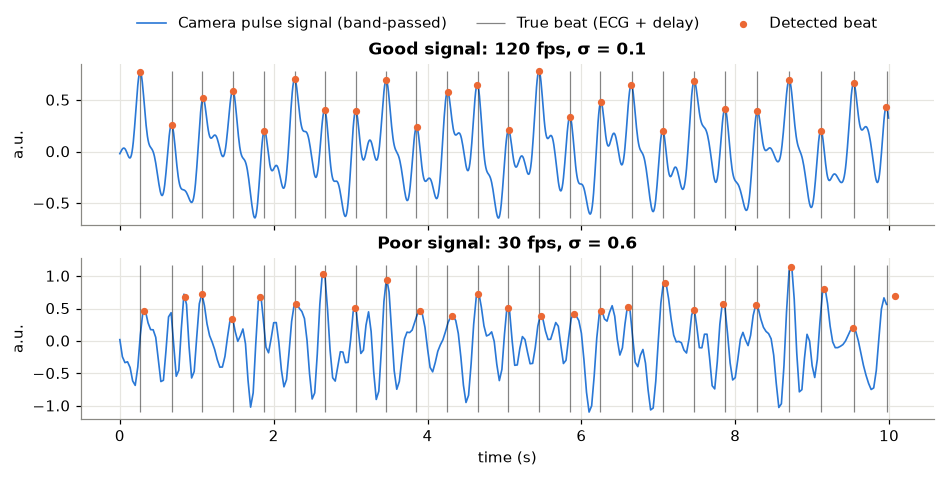

In [9]:
# Visual check: one 10 s stretch of a real infant's beats through the camera model
beats0 = pics_windows[3][1]
fig, axes = plt.subplots(2, 1, figsize=(10, 4.2), sharex=True)
for ax, (fps, sigma, title) in zip(axes, [(120, 0.1, 'Good signal: 120 fps, σ = 0.1'), (30, 0.6, 'Poor signal: 30 fps, σ = 0.6')]):
    x, _ = synth_ppg(beats0, fps, sigma)
    tb, _ = detect_beats(x, fps)
    tt = np.arange(len(x)) / fps
    m = tt < 10
    y = bandpass(x, 0.8, min(6.0, fps / 2 - 1), fps)
    ax.plot(tt[m], y[m], color=BLUE, lw=1.1, label='Camera pulse signal (band-passed)')
    tr = beats0[beats0 < 10] + PULSE_DELAY
    ax.vlines(tr, y[m].min(), y[m].max(), color='#0b0b0b', lw=0.8, alpha=0.5, label='True beat (ECG + delay)')
    d = tb[tb < 10] + PULSE_DELAY
    ax.scatter(d, np.interp(d, tt, y), color=ORANGE, s=14, zorder=3, label='Detected beat')
    ax.set_title(title); ax.set_ylabel('a.u.')
axes[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.12), ncol=3)
axes[1].set_xlabel('time (s)')
save(fig, 'B0_camera_model'); plt.show()

---
## Part B · Experiment E1: frame rate, noise and HRV feature error

**Question.** At what frame rate and signal quality do HeRO-type features stop being reliable?

**Back-of-envelope.** At 30 fps one frame lasts 33 ms. A neonatal beat at 150 bpm lasts 400 ms, so a single frame is about **8% of a beat**. Uniform quantisation gives a timing error of 33/√12 ≈ 9.6 ms per beat, and the difference of two beats has √2 times that, about 13.6 ms. **That is comparable to the RMSSD of a preterm infant itself.**

**Method.** For every 5-minute window we compute the features from the true ECG beats (reference). We then compute them again from the camera model at 30, 60 and 120 fps, with and without sub-frame interpolation, at three noise levels. The error is the median relative error across windows.

In [10]:
FPS_LIST = [30, 60, 120]
SIGMAS = [0.1, 0.3, 0.6]
E1_WINDOWS = [w for k, w in enumerate(pics_windows) if k % 3 == 0]   # 100 windows, all infants

ref_feats = pd.DataFrame([ibi_features(np.diff(b)) for _, b in E1_WINDOWS])

t0 = time.time()
e1_rows, timing_rows = [], []
for fps in FPS_LIST:
    for sigma in SIGMAS:
        for interp in [False, True]:
            if not interp and sigma != 0.1:
                continue                                  # no-interp only needed at low noise
            feats = []
            for _, b in E1_WINDOWS:
                ibi, valid, _ = camera_ibis(b, fps, sigma, interp)
                feats.append(ibi_features(ibi, valid))
            feats = pd.DataFrame(feats)
            rel = (feats - ref_feats).abs() / ref_feats.abs().replace(0, np.nan)
            row = {'fps': fps, 'sigma': sigma, 'interp': interp}
            row.update((rel.drop(columns='decels').median() * 100).to_dict())
            row['decels (abs err / window)'] = (feats.decels - ref_feats.decels).abs().mean()
            e1_rows.append(row)
        # beat-timing error at this setting (matched beats within 100 ms)
        errs = []
        for _, b in E1_WINDOWS[:30]:
            x, _ = synth_ppg(b, fps, sigma)
            tb, _ = detect_beats(x, fps)
            j = np.clip(np.searchsorted(tb, b), 1, len(tb) - 1)
            near = np.where(np.abs(tb[j] - b) < np.abs(tb[j - 1] - b), tb[j], tb[j - 1])
            e = near - b
            errs.append(e[np.abs(e) < 0.1])
        e = np.concatenate(errs)
        timing_rows.append({'fps': fps, 'sigma': sigma, 'RMS timing error (ms)': 1000 * np.sqrt(np.mean(e ** 2))})
e1 = pd.DataFrame(e1_rows)
print(f'E1 done in {time.time() - t0:.0f} s')
print('Median relative feature error (%) vs ECG reference; deceleration count as absolute error per window:')
display(e1.round(1))
display(pd.DataFrame(timing_rows).pivot(index='fps', columns='sigma', values='RMS timing error (ms)').round(1))
print('Reference (ECG) feature medians:', ref_feats.median().round(2).to_dict())

E1 done in 64 s
Median relative feature error (%) vs ECG reference; deceleration count as absolute error per window:


,fps,sigma,interp,mean_hr,sdnn_ms,rmssd_ms,asymmetry,samp_en,decels (abs err / window)
0,30,0.1,False,0.0,26.5,267.2,82.0,49.5,0.5
1,30,0.1,True,0.0,11.1,136.3,29.3,138.8,0.5
2,30,0.3,True,0.7,116.7,749.8,58.4,171.1,2.3
3,30,0.6,True,3.5,302.7,1426.6,64.5,182.4,21.7
4,60,0.1,False,0.0,8.5,134.6,53.8,57.4,0.4
5,60,0.1,True,0.0,5.0,65.4,15.5,112.2,0.2
6,60,0.3,True,0.1,40.6,377.8,39.6,174.0,0.6
7,60,0.6,True,1.3,199.4,1113.6,58.7,153.1,7.8
8,120,0.1,False,0.0,4.8,78.6,31.4,84.7,0.3
9,120,0.1,True,0.0,4.6,54.5,14.4,91.1,0.4


sigma,0.1,0.3,0.6
fps,,,
30,6.1,18.2,33.1
60,4.4,11.1,24.3
120,3.4,7.6,16.7


Reference (ECG) feature medians: {'mean_hr': 147.47, 'sdnn_ms': 21.78, 'rmssd_ms': 8.34, 'asymmetry': 1.35, 'samp_en': 0.65, 'decels': 0.0}


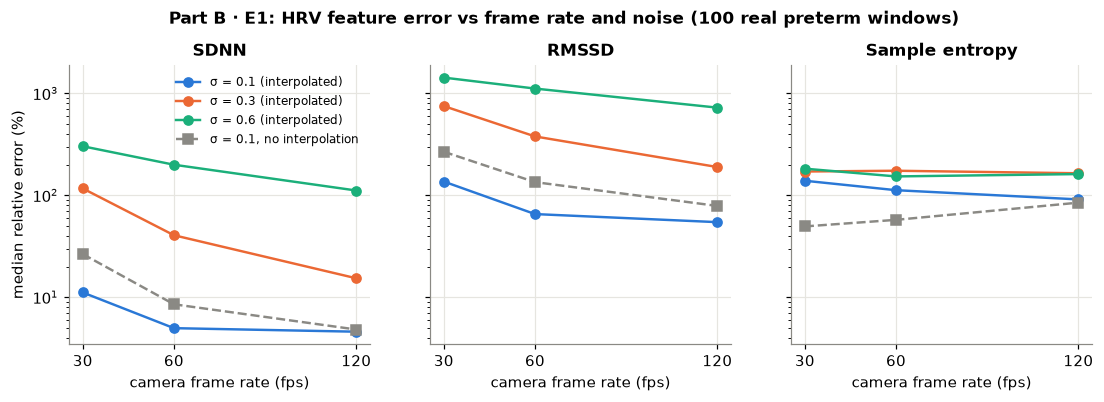

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
for ax, feat, title in zip(axes, ['sdnn_ms', 'rmssd_ms', 'samp_en'], ['SDNN', 'RMSSD', 'Sample entropy']):
    for sigma, col in zip(SIGMAS, [BLUE, ORANGE, AQUA]):
        d = e1[(e1.sigma == sigma) & e1.interp]
        ax.plot(d.fps, d[feat], marker='o', ms=6, color=col, label=f'σ = {sigma} (interpolated)')
    d = e1[(e1.sigma == 0.1) & ~e1.interp]
    ax.plot(d.fps, d[feat], marker='s', ms=6, color=GREY, ls='--', label='σ = 0.1, no interpolation')
    ax.set_xticks(FPS_LIST); ax.set_xlabel('camera frame rate (fps)')
    ax.set_title(title); ax.set_yscale('log')
axes[0].set_ylabel('median relative error (%)')
axes[0].legend(loc='upper right', fontsize=8)
fig.suptitle('Part B · E1: HRV feature error vs frame rate and noise (100 real preterm windows)', fontweight='bold', y=1.03)
save(fig, 'B1_fps_feature_error'); plt.show()

**Part B, takeaways**
* The preterm reference RMSSD is only **~8 ms** (median). Beat timing error ranges from **~3 ms (120 fps, clean) to ~33 ms (30 fps, noisy)**, so beat-to-beat features are swamped first.
* At low noise, **SDNN error falls from ~27% (30 fps, no interpolation) to ~5% (60 fps, interpolated)**. Parabolic peak interpolation is the cheap alternative to a faster camera.
* Noise matters as much as frame rate. At σ = 0.6, even 120 fps gives > 100% SDNN error, and false decelerations appear.
* **RMSSD and sample entropy are not reliable from a camera at any setting we tested.** SDNN, asymmetry and the deceleration count are the realistic camera features.
* **Design specification from E1:** ≥ 60 fps with peak interpolation, plus a quality gate.

---
## Part C · Experiment E2: ML risk model (methodology step 10)

**Question.** If a baby's heart rate shows the HeRO sepsis signature, can a model still detect it **after the signal has passed through a camera**?

**Building the dataset.** We have no sepsis labels (no public neonatal dataset has them), so we construct a controlled test:
* **Class 0, "normal":** real 5-minute preterm windows, unchanged. These already include the infants' natural bradycardias, which makes the task harder.
* **Class 1, "sepsis-like":** a *different* real window with the HeRO signature injected, at a random strength (Griffin & Moorman 2001):
  * **reduced variability.** Deviations from the slow trend are scaled by α ∈ [0.35, 0.8].
  * **transient decelerations.** 1–4 HR dips of 25–50% lasting 4–12 s.

**Models.** Logistic regression (as in HeRO and Leon 2021) and a random forest on the 6 features. **Validation is leave-one-infant-out**: the model never sees the test infant during training.

**Two deployment scenarios:**
1. **Train and test on camera features.** The model is trained on camera data of the same quality.
2. **Train on ECG, test on camera.** This is realistic: existing models (HeRO) were built on clean ECG and would simply be applied to camera input.

In [12]:
def inject_sepsis(beats, rng):
    """Inject a HeRO-like pattern (reduced variability + transient decelerations) into real beat times."""
    ibi = np.diff(beats)
    trend = pd.Series(ibi).rolling(41, center=True, min_periods=1).mean().values
    alpha = rng.uniform(0.35, 0.8)
    ibi = trend + alpha * (ibi - trend)                                  # reduced variability
    t = np.cumsum(ibi)
    for _ in range(rng.integers(1, 5)):                                  # transient decelerations
        c, dur, depth = rng.uniform(20, WIN_S - 20), rng.uniform(4, 12), rng.uniform(0.25, 0.5)
        shape = np.clip(1 - np.abs(t - c) / (dur / 2), 0, 1)             # triangular dip
        shape = np.sin(shape * np.pi / 2) ** 2                           # smooth edges
        ibi = ibi / (1 - depth * shape)                                  # HR drops by `depth` at the centre
    nb = np.concatenate([[beats[0]], beats[0] + np.cumsum(ibi)])
    return nb[nb < WIN_S]

# Build the labelled set: each window is used once, either as normal or as sepsis-like
X_beats, y_lab, groups = [], [], []
for k, (inf, b) in enumerate(pics_windows):
    if k % 2 == 0:
        X_beats.append(b); y_lab.append(0)
    else:
        X_beats.append(inject_sepsis(b, RNG)); y_lab.append(1)
    groups.append(inf)
y_lab, groups = np.array(y_lab), np.array(groups)
print(f'{len(y_lab)} windows: {np.sum(y_lab == 0)} normal, {np.sum(y_lab == 1)} sepsis-like, {len(set(groups))} infants')

300 windows: 150 normal, 150 sepsis-like, 10 infants


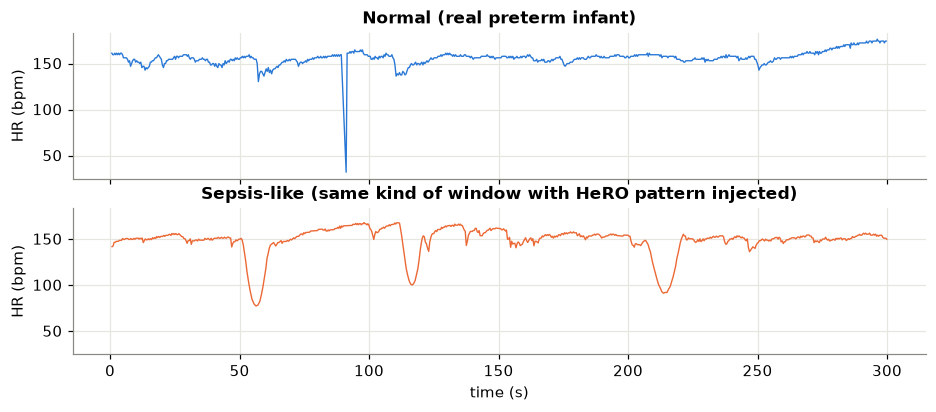

In [13]:
# Example: one normal and one sepsis-like window (heart rate over 5 min)
fig, axes = plt.subplots(2, 1, figsize=(10, 3.8), sharex=True, sharey=True)
for ax, cls, col, title in zip(axes, [0, 1], [BLUE, ORANGE], ['Normal (real preterm infant)', 'Sepsis-like (same kind of window with HeRO pattern injected)']):
    b = X_beats[int(np.flatnonzero(y_lab == cls)[2])]
    ax.plot(b[1:], 60 / np.diff(b), color=col, lw=0.9)
    ax.set_title(title); ax.set_ylabel('HR (bpm)')
axes[1].set_xlabel('time (s)')
save(fig, 'C0_example_windows'); plt.show()

In [14]:
def feature_table(fps=None, sigma=None, motion_frac=0.0, gate=False, seed=0):
    """Features for every window: from ECG beats (fps=None) or through the camera model."""
    rng = np.random.default_rng(seed)
    rows, cov = [], []
    for b in X_beats:
        if fps is None:
            rows.append(ibi_features(np.diff(b))); cov.append(1.0)
        else:
            ibi, valid, c = camera_ibis(b, fps, sigma, motion_frac=motion_frac, gate=gate, rng=rng)
            rows.append(ibi_features(ibi, valid)); cov.append(c)
    F = pd.DataFrame(rows)
    return F.fillna(F.median()), float(np.mean(cov))


MODELS = {
    'Logistic regression': lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000)),
    'Random forest': lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1),
}
CV = GroupKFold(n_splits=10)                                             # 10 infants -> leave-one-infant-out


def auroc_cv(F, model):
    p = cross_val_predict(MODELS[model](), F.values, y_lab, groups=groups, cv=CV, method='predict_proba')[:, 1]
    return roc_auc_score(y_lab, p), p


def auroc_transfer(F_train, F_test, model):
    """Train on ECG features of the other infants, test on camera features of the held-out infant."""
    p = np.zeros(len(y_lab))
    for tr, te in CV.split(F_train, y_lab, groups):
        m = MODELS[model]().fit(F_train.values[tr], y_lab[tr])
        p[te] = m.predict_proba(F_test.values[te])[:, 1]
    return roc_auc_score(y_lab, p), p

In [15]:
t0 = time.time()
F_ecg, _ = feature_table()
cam = {(fps, s): feature_table(fps, s, seed=fps * 10 + int(s * 10))[0] for fps in FPS_LIST for s in SIGMAS}
print(f'features for {len(cam) + 1} conditions in {time.time() - t0:.0f} s')

e2_rows, roc_store = [], {}
for model in MODELS:
    auc, p = auroc_cv(F_ecg, model)
    roc_store[(model, 'ECG')] = p
    e2_rows.append({'model': model, 'input': 'ECG (reference)', 'fps': '-', 'sigma': '-', 'AUROC train=test source': auc, 'AUROC train ECG -> test camera': auc})
    for (fps, s), F in cam.items():
        auc_cam, p = auroc_cv(F, model)
        auc_tr, _ = auroc_transfer(F_ecg, F, model)
        roc_store[(model, fps, s)] = p
        e2_rows.append({'model': model, 'input': 'camera', 'fps': fps, 'sigma': s,
                        'AUROC train=test source': auc_cam, 'AUROC train ECG -> test camera': auc_tr})
e2 = pd.DataFrame(e2_rows)
display(e2.round(3))

features for 10 conditions in 129 s


,model,input,fps,sigma,AUROC train=test source,AUROC train ECG -> test camera
0,Logistic regression,ECG (reference),-,-,0.940,0.940
1,Logistic regression,camera,30,0.1,0.884,0.833
2,Logistic regression,camera,30,0.3,0.795,0.723
3,Logistic regression,camera,30,0.6,0.615,0.591
4,Logistic regression,camera,60,0.1,0.843,0.847
5,Logistic regression,camera,60,0.3,0.852,0.762
6,Logistic regression,camera,60,0.6,0.777,0.543
7,Logistic regression,camera,120,0.1,0.854,0.858
8,Logistic regression,camera,120,0.3,0.864,0.820
9,Logistic regression,camera,120,0.6,0.831,0.659


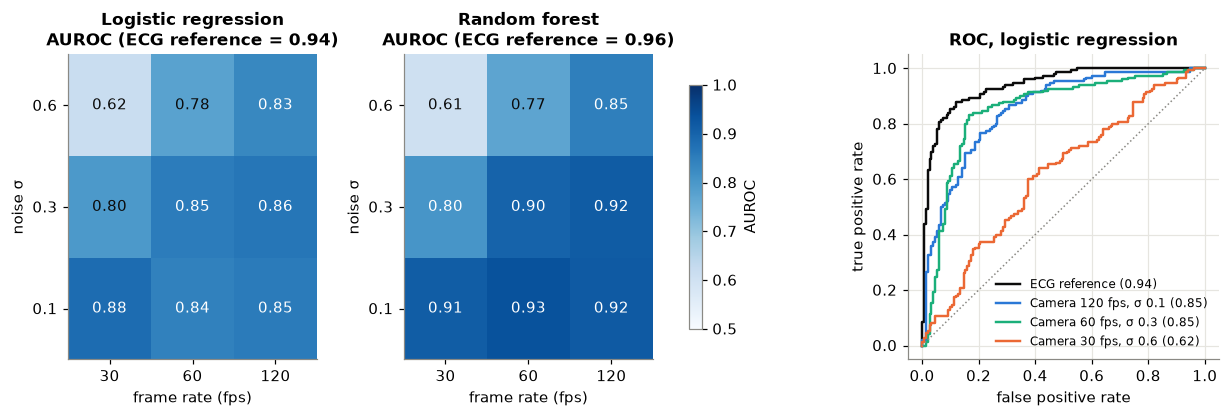

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6), gridspec_kw={'wspace': 0.35})
for ax, (model, col) in zip(axes[:2], [('Logistic regression', 'AUROC train=test source'), ('Random forest', 'AUROC train=test source')]):
    d = e2[(e2.model == model) & (e2.input == 'camera')].pivot(index='sigma', columns='fps', values=col)
    im = ax.imshow(d.values, cmap='Blues', vmin=0.5, vmax=1.0, origin='lower', aspect='auto')
    for (r, c), v in np.ndenumerate(d.values):
        ax.text(c, r, f'{v:.2f}', ha='center', va='center', fontsize=10,
                color='white' if v > 0.8 else '#0b0b0b')
    ax.set_xticks(range(3), FPS_LIST); ax.set_yticks(range(3), SIGMAS)
    ax.set_xlabel('frame rate (fps)'); ax.set_ylabel('noise σ'); ax.grid(False)
    ecg_auc = e2[(e2.model == model) & (e2.input != 'camera')][col].iloc[0]
    ax.set_title(f'{model}\nAUROC (ECG reference = {ecg_auc:.2f})')
fig.colorbar(im, ax=axes[:2], shrink=0.8, label='AUROC')

ax = axes[2]
model = 'Logistic regression'
for key, col, lab in [((model, 'ECG'), '#0b0b0b', 'ECG reference'), ((model, 120, 0.1), BLUE, 'Camera 120 fps, σ 0.1'),
                      ((model, 60, 0.3), AQUA, 'Camera 60 fps, σ 0.3'), ((model, 30, 0.6), ORANGE, 'Camera 30 fps, σ 0.6')]:
    fpr, tpr, _ = roc_curve(y_lab, roc_store[key])
    ax.plot(fpr, tpr, color=col, label=f'{lab} ({roc_auc_score(y_lab, roc_store[key]):.2f})')
ax.plot([0, 1], [0, 1], color=GREY, ls=':', lw=1)
ax.set_xlabel('false positive rate'); ax.set_ylabel('true positive rate')
ax.set_title('ROC, logistic regression'); ax.legend(loc='lower right', fontsize=8)
save(fig, 'C1_auroc_vs_camera_quality'); plt.show()

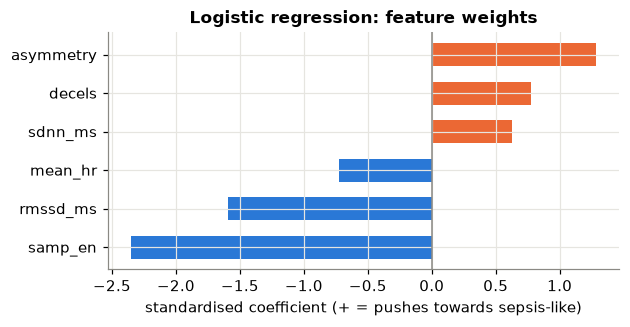

In [17]:
# What did the logistic regression learn? (standardised coefficients, ECG-trained model)
lr = MODELS['Logistic regression']().fit(F_ecg.values, y_lab)
coef = pd.Series(lr[-1].coef_[0], index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(coef.index, coef.values, color=[ORANGE if v > 0 else BLUE for v in coef.values], height=0.6)
ax.axvline(0, color=GREY, lw=1)
ax.set_xlabel('standardised coefficient (+ = pushes towards sepsis-like)')
ax.set_title('Logistic regression: feature weights')
save(fig, 'C2_feature_weights'); plt.show()

**Part C, takeaways**
* On clean ECG features, the HeRO-type signature is detected with **AUROC ≈ 0.94 (logistic regression) and ≈ 0.96 (random forest)**, leave-one-infant-out.
* **Through a good camera (≥ 60 fps, σ ≤ 0.3) most of it survives: AUROC ≈ 0.85–0.92.** At 30 fps with high noise it collapses to ≈ 0.6, close to chance. This is the answer to objective O2.
* *Train on ECG, test on camera* is clearly worse at high noise (e.g. ≈ 0.54–0.57 at 60 fps, σ 0.6). Existing ECG-trained models (HeRO-style) **cannot simply be plugged into a camera**; they need camera-domain training or a quality gate.
* The feature weights match the clinical story: lower variability and entropy, plus more decelerations and asymmetry, push the risk up.
* **Limitation:** the sepsis-like class is synthetic. This experiment shows the *signal survives*; it does not show sepsis detection.

---
## Part D · Experiment E4: confidence-gate ablation

**Question.** Real NICU video is full of motion (only ~56% usable, Svoboda 2024). Does carrying our confidence gate into the feature stage help?

**Method.** At 60 fps and σ = 0.3, we add motion bursts covering 10%, 25% and 40% of each window. We then compute features **without** the gate (all detected beats) and **with** the gate (only intervals whose both beats pass the quality check: template correlation ≥ 0.8 and normal amplitude). We compare feature error against the ECG reference, coverage, and the AUROC of the risk model.

In [18]:
t0 = time.time()
e4_rows = []
for mf in [0.10, 0.25, 0.40]:
    for gate in [False, True]:
        F, cov = feature_table(60, 0.3, motion_frac=mf, gate=gate, seed=int(mf * 100))
        rel = (F - F_ecg).abs() / F_ecg.abs().replace(0, np.nan)
        auc, _ = auroc_cv(F, 'Logistic regression')
        e4_rows.append({'motion %': int(mf * 100), 'gate': 'on' if gate else 'off', 'coverage %': 100 * cov,
                        'SDNN err %': 100 * rel.sdnn_ms.median(), 'RMSSD err %': 100 * rel.rmssd_ms.median(),
                        'decel count err': (F.decels - F_ecg.decels).abs().mean(), 'AUROC (LR)': auc})
e4 = pd.DataFrame(e4_rows)
print(f'E4 done in {time.time() - t0:.0f} s')
display(e4.round(2))

E4 done in 65 s


,motion %,gate,coverage %,SDNN err %,RMSSD err %,decel count err,AUROC (LR)
0,10,off,97.26,70.99,564.99,6.07,0.85
1,10,on,76.44,15.46,233.28,0.38,0.90
2,25,off,91.62,123.14,791.33,13.21,0.76
3,25,on,58.90,24.20,250.66,0.73,0.84
4,40,off,85.51,227.72,1250.61,25.66,0.68
5,40,on,21.84,39.53,263.34,1.46,0.68


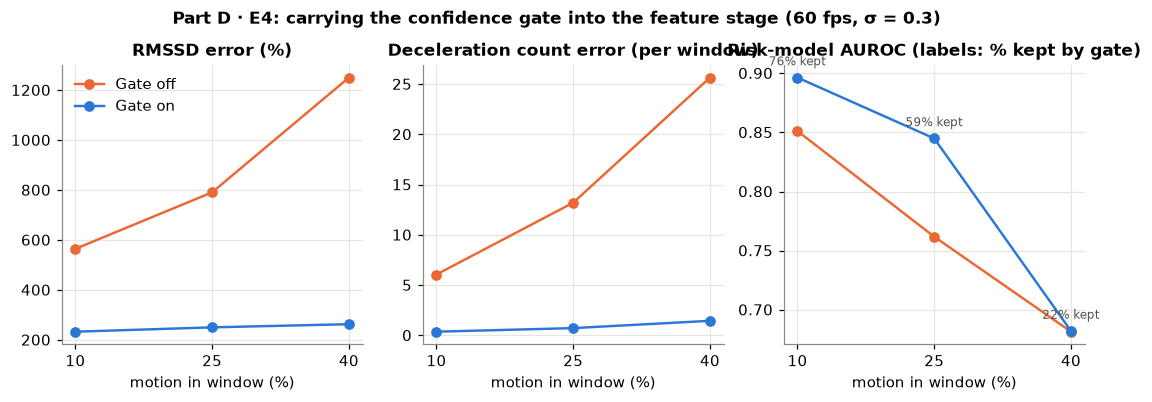

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
mot = sorted(e4['motion %'].unique())
for ax, col, title in zip(axes, ['RMSSD err %', 'decel count err', 'AUROC (LR)'],
                          ['RMSSD error (%)', 'Deceleration count error (per window)', 'Risk-model AUROC (labels: % kept by gate)']):
    for g, c, lab in [('off', ORANGE, 'Gate off'), ('on', BLUE, 'Gate on')]:
        d = e4[e4.gate == g]
        ax.plot(d['motion %'], d[col], marker='o', ms=6, color=c, label=lab)
        if col == 'AUROC (LR)' and g == 'on':
            for xm, ym, cv in zip(d['motion %'], d[col], d['coverage %']):
                ax.annotate(f'{cv:.0f}% kept', (xm, ym), textcoords='offset points',
                            xytext=(0, 8), ha='center', fontsize=8, color='#52514e')
    ax.set_xticks(mot); ax.set_xlabel('motion in window (%)'); ax.set_title(title)
axes[0].legend()
fig.suptitle('Part D · E4: carrying the confidence gate into the feature stage (60 fps, σ = 0.3)', fontweight='bold', y=1.03)
save(fig, 'D1_gate_ablation'); plt.show()

**Part D, takeaways**
* Without the gate, motion creates false beats and **false decelerations (~6–26 per window)**, which are exactly the features the sepsis model relies on.
* With the gate, the false decelerations fall to **< 1.5 per window**, SDNN error falls several-fold, and **risk-model AUROC rises (≈ 0.85 → 0.90 at 10% motion; ≈ 0.76 → 0.84 at 25%)**.
* The cost is coverage: at 40% motion the gate keeps only ~22% of beats and the AUROC no longer improves. **Reporting coverage is part of the output** (methodology step 11), and the system should say *"not enough clean signal"* instead of guessing.

---
## Summary for the review

| Slide claim | Evidence in this notebook |
|---|---|
| Pipeline validated on real PPG | Part A table and figure A1 (12 recordings, chest-ECG reference) |
| Tracker can fail silently, so a confidence gate is essential | Figure A2 and the failure count printed under it |
| 30 fps ≈ 8% of a beat; frame rate must rise for HRV | Part B table and figure B1 |
| Do sepsis-like HR patterns survive camera noise? (O2) | Part C heatmaps and ROC (figure C1) |
| Carry the confidence gate into the feature stage (O4) | Part D table and figure D1 |

**Pending (as on the review slides):** E3, beat detection on real newborn video (NBHR / VideoPulse; access requested), and E5, a NICU pilot with a hospital partner, ethics approval and culture-confirmed labels.

All figures are saved to the `figures/` folder for the report.

In [20]:
pd.DataFrame(e2_rows).to_csv(f'{FIG_DIR}/e2_auroc.csv', index=False)
spc.to_csv(f'{FIG_DIR}/partA_spc_errors.csv')
e1.to_csv(f'{FIG_DIR}/e1_feature_error.csv', index=False)
e4.to_csv(f'{FIG_DIR}/e4_gate.csv', index=False)
print(sorted(os.listdir(FIG_DIR)))

['A1_stage_errors.png', 'A2_silent_failure.png', 'B0_camera_model.png', 'B1_fps_feature_error.png', 'C0_example_windows.png', 'C1_auroc_vs_camera_quality.png', 'C2_feature_weights.png', 'D1_gate_ablation.png', 'e1_feature_error.csv', 'e2_auroc.csv', 'e4_gate.csv', 'partA_spc_errors.csv']
